<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Pratica6Questao3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

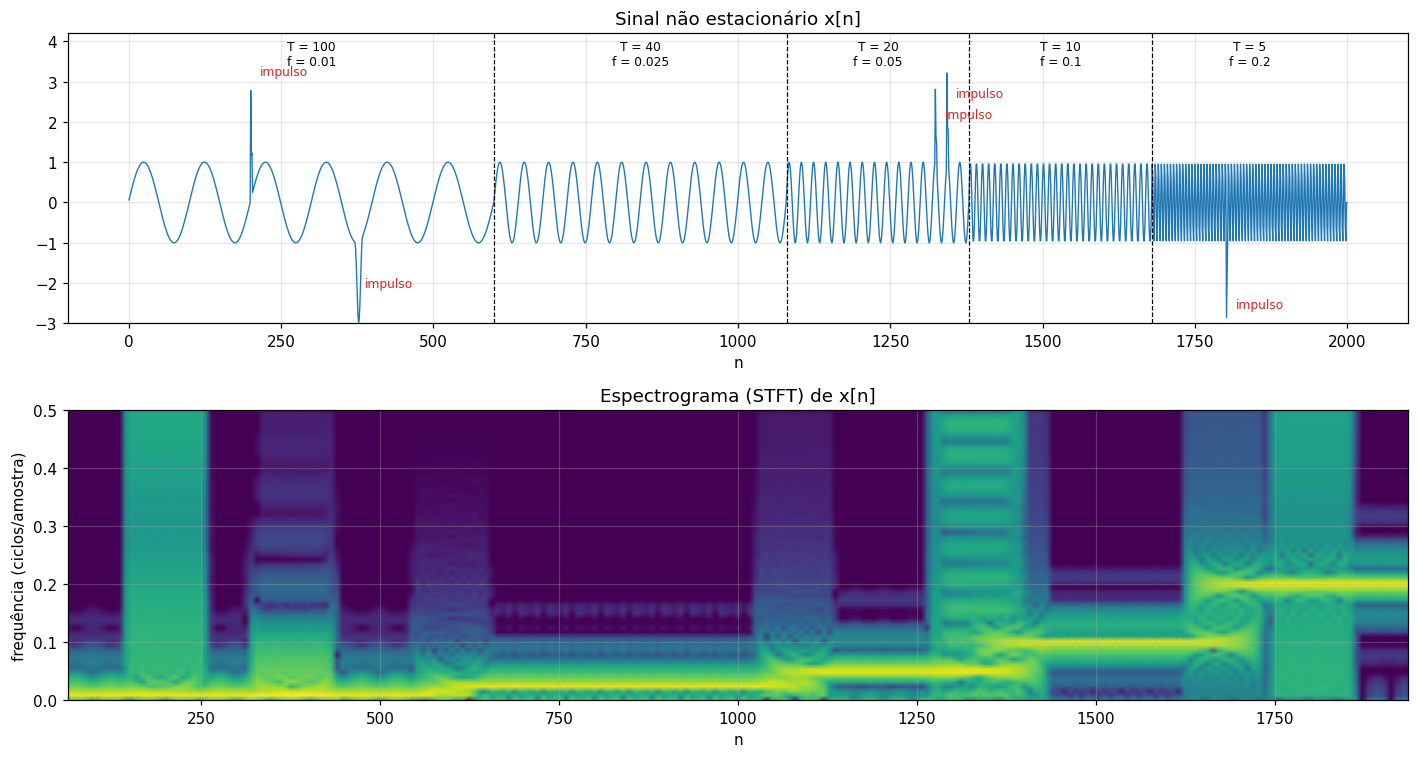

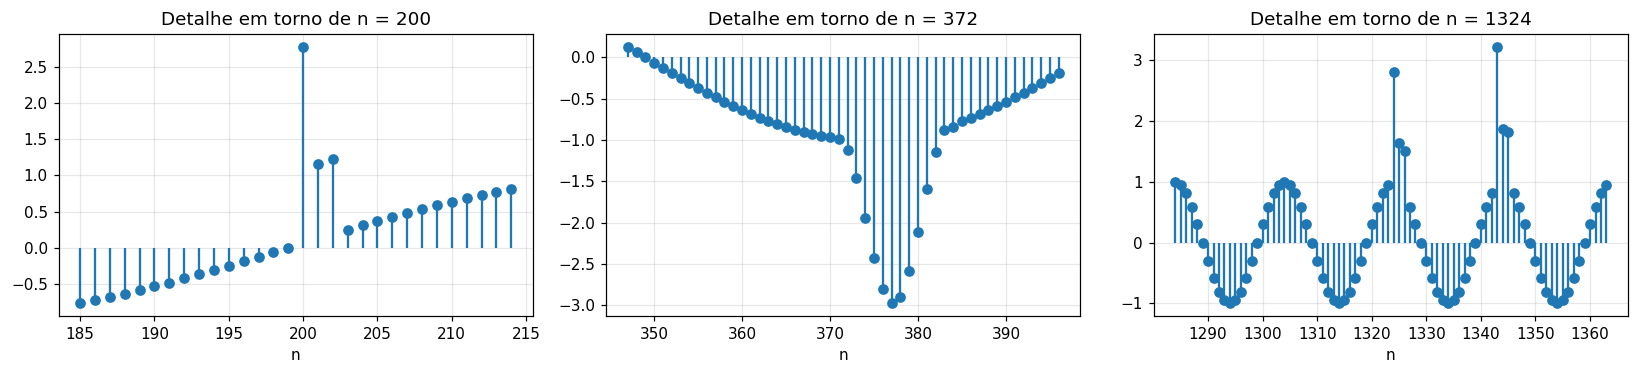

Wavelet: bior4.4 | família: Biorthogonal | biortogonal: True | ortogonal: False

Análise passa-baixas (h0)  (9 coeficientes não nulos)
  h[1] =  0.0378284555
  h[2] = -0.0238494650
  h[3] = -0.1106244044
  h[4] =  0.3774028556
  h[5] =  0.8526986790
  h[6] =  0.3774028556
  h[7] = -0.1106244044
  h[8] = -0.0238494650
  h[9] =  0.0378284555
  soma =  1.414214   soma*(-1)^n =  0.000000

Análise passa-altas (h1)  (7 coeficientes não nulos)
  h[1] = -0.0645388826
  h[2] =  0.0406894176
  h[3] =  0.4180922732
  h[4] = -0.7884856164
  h[5] =  0.4180922732
  h[6] =  0.0406894176
  h[7] = -0.0645388826
  soma = -0.000000   soma*(-1)^n = -1.414214

Síntese passa-baixas (g0)  (7 coeficientes não nulos)
  h[1] = -0.0645388826
  h[2] = -0.0406894176
  h[3] =  0.4180922732
  h[4] =  0.7884856164
  h[5] =  0.4180922732
  h[6] = -0.0406894176
  h[7] = -0.0645388826
  soma =  1.414214   soma*(-1)^n =  0.000000

Síntese passa-altas (g1)  (9 coeficientes não nulos)
  h[1] = -0.0378284555
  h[2] = -0.023

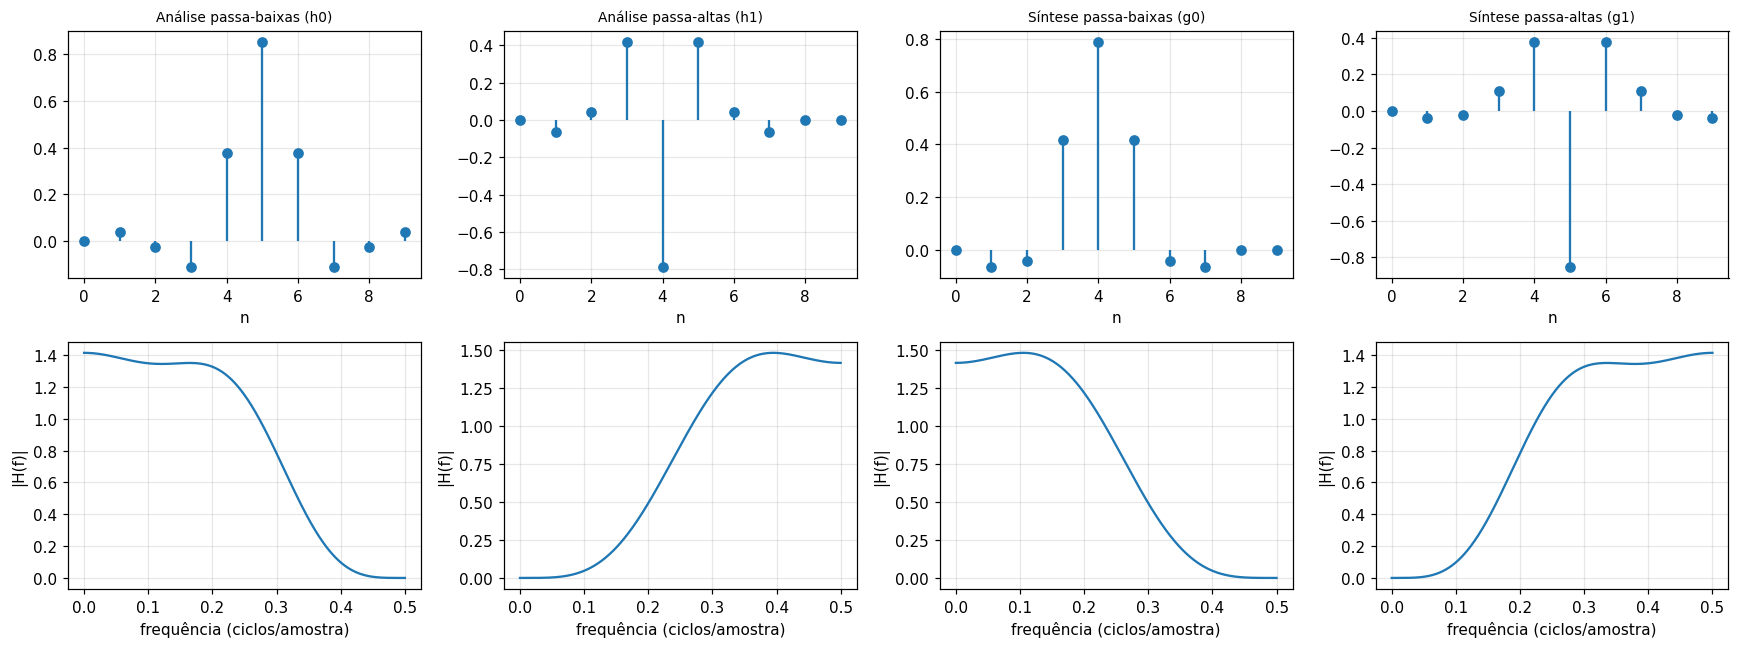

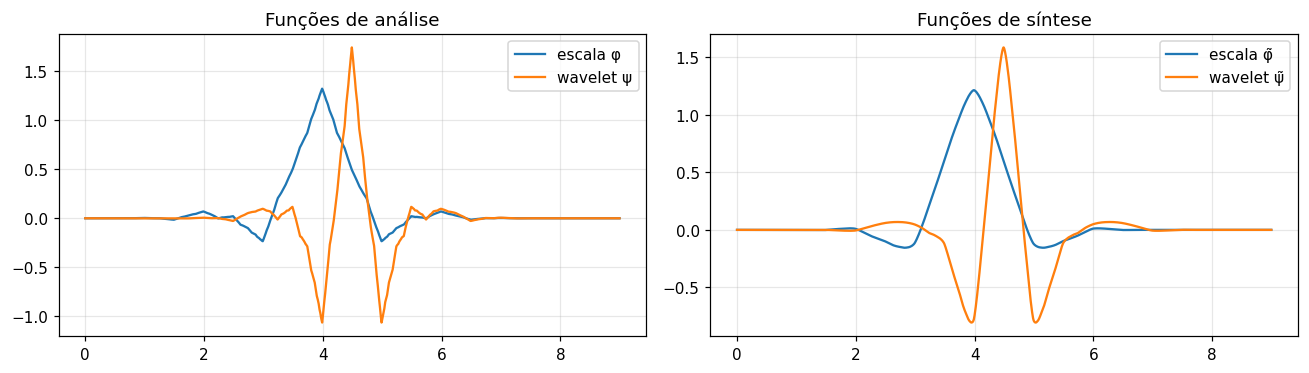

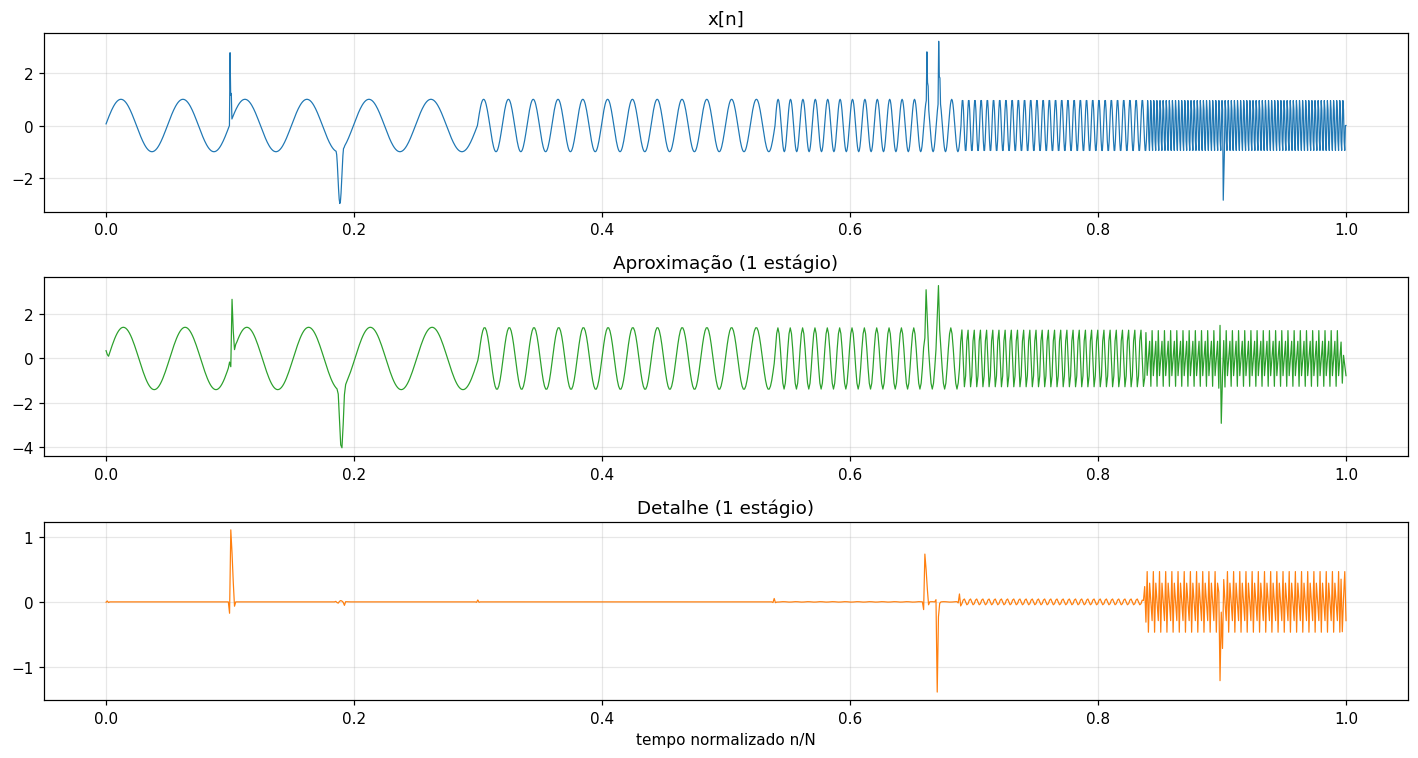

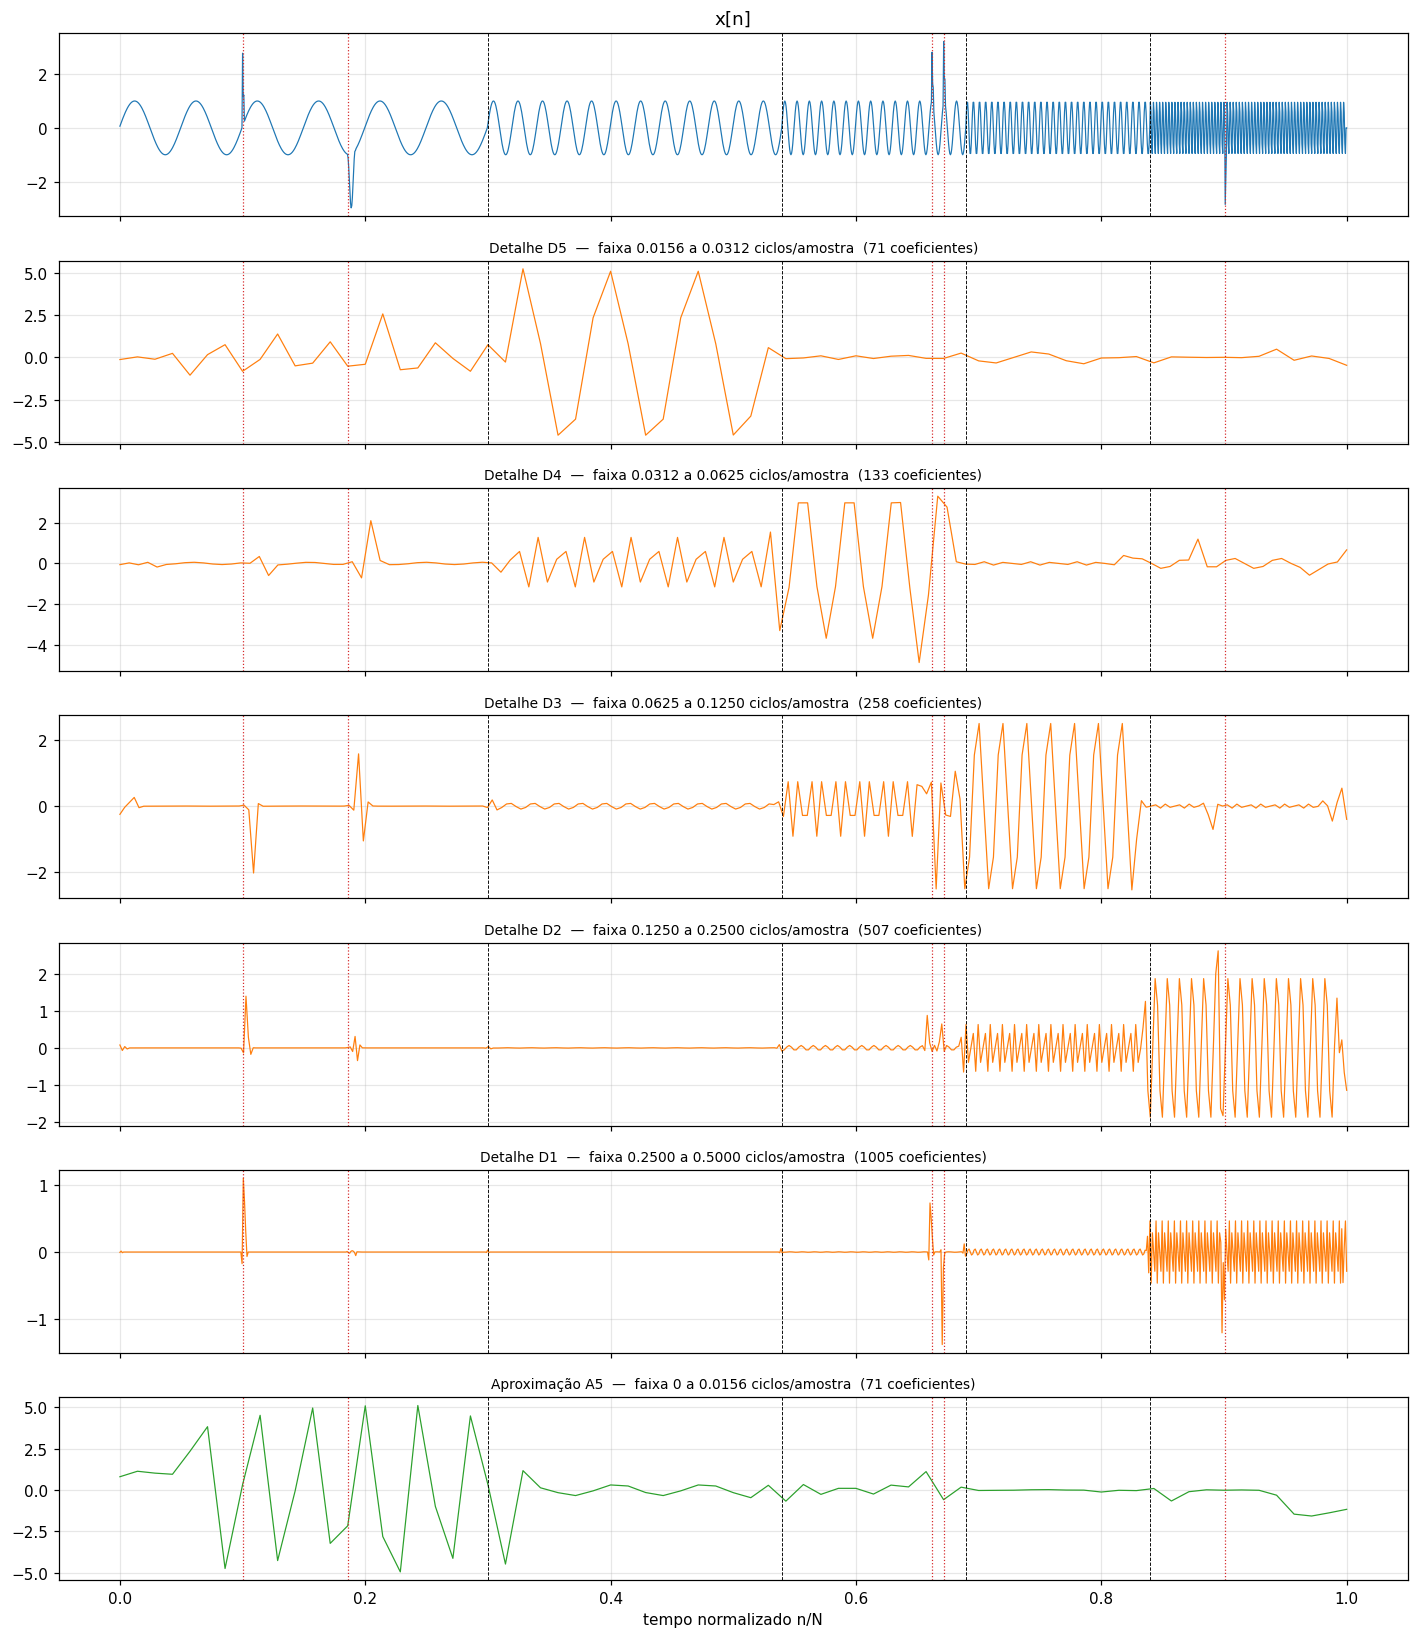

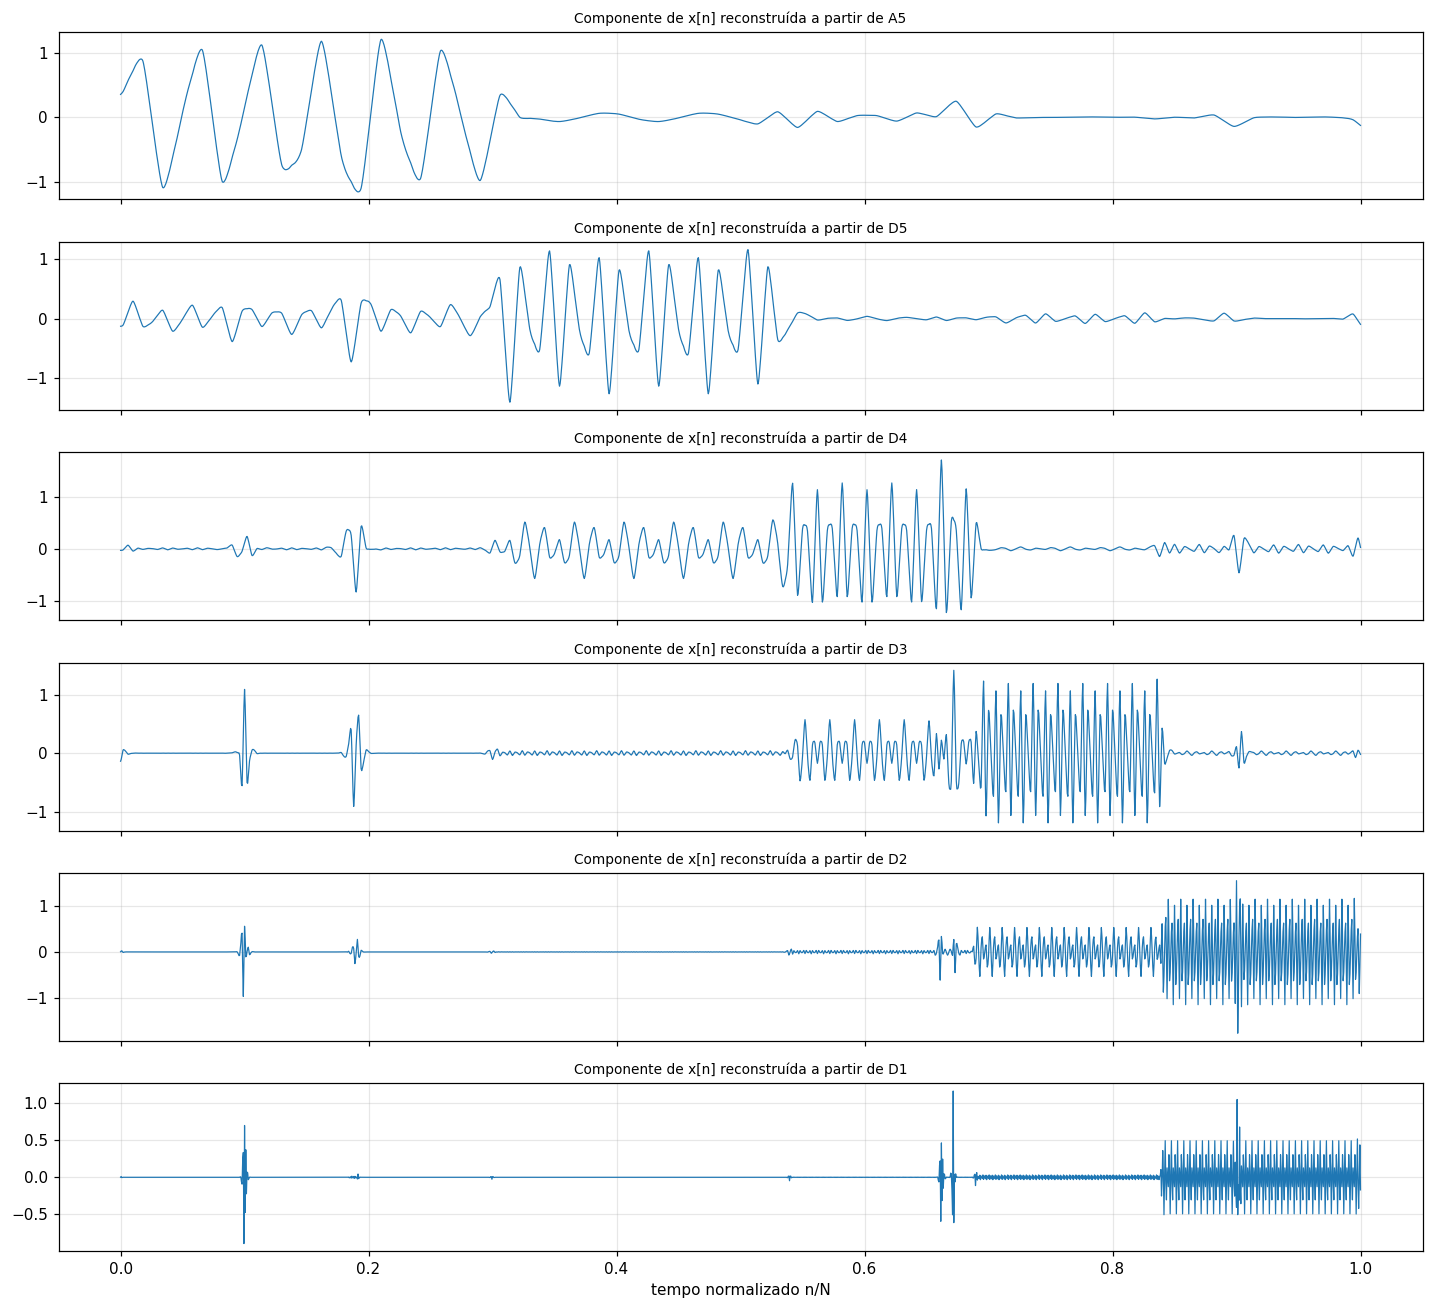


Erro máximo de reconstrução perfeita: 7.637890320211227e-12

Energia (%) de cada trecho do sinal em cada sub-banda
        T=100     T=40     T=20     T=10      T=5
  A5     88.7      1.5      1.3      0.2      0.4
  D5      5.5     82.0      0.2      0.4      0.1
  D4      1.9     16.4     79.2      0.9      1.5
  D3      2.7      0.1     16.6     83.0      0.7
  D2      0.7      0.0      0.9     15.3     81.4
  D1      0.6      0.0      1.8      0.2     15.9


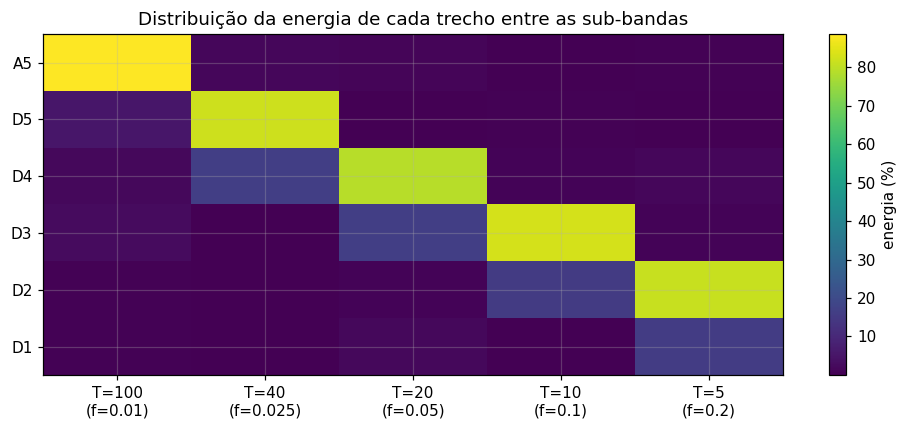

In [1]:
import subprocess, sys
try:
    import pywt
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'PyWavelets'])
    import pywt
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


N = 2000
t = np.arange(N + 1)
x = np.zeros_like(t, dtype=np.float64)

pos_sin = np.array([0, 600, 1080, 1380, 1680, 2000])
T_sin = np.array([100, 40, 20, 10, 5])
for i in range(5):
    m, n = pos_sin[i], pos_sin[i + 1]
    x[m:n] = np.sin(2 * np.pi * np.arange(1, n - m + 1) / T_sin[i])

amp_imp = np.array([3, -2, 2, 2.5, -2.5])
pos_imp = np.array([200, 372, 1324, 1343, 1802])
T_imp = np.array([5, 25, 5, 5, 5])
for i in range(5):
    m = pos_imp[i]
    n = pos_imp[i] + int(T_imp[i] / 2)
    x[m:n + 1] += amp_imp[i] * np.sin(2 * np.pi * np.arange(1, n - m + 2) / T_imp[i]) ** 2


fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(t, x, lw=0.9)
for p in pos_sin[1:-1]:
    ax[0].axvline(p, color='k', ls='--', lw=0.8)
for p, a in zip(pos_imp, amp_imp):
    ax[0].annotate('impulso', (p, a), xytext=(p + 15, a * 1.05), fontsize=8, color='C3')
for i in range(5):
    ax[0].text((pos_sin[i] + pos_sin[i + 1]) / 2, 3.4, f'T = {T_sin[i]}\nf = {1/T_sin[i]:g}', ha='center', fontsize=8)
ax[0].set_ylim(-3, 4.2)
ax[0].set_title('Sinal não estacionário x[n]')
ax[0].set_xlabel('n')
f_s, t_s, S = spectrogram(x, fs=1.0, nperseg=128, noverlap=120)
ax[1].pcolormesh(t_s, f_s, 10 * np.log10(S + 1e-12), shading='gouraud', vmin=-50)
ax[1].set_title('Espectrograma (STFT) de x[n]')
ax[1].set_xlabel('n')
ax[1].set_ylabel('frequência (ciclos/amostra)')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, p, w in zip(ax, [200, 372, 1324], [15, 25, 40]):
    a.stem(t[p - w:p + w], x[p - w:p + w], basefmt=' ')
    a.set_title(f'Detalhe em torno de n = {p}')
    a.set_xlabel('n')
plt.tight_layout()
plt.show()


wav = pywt.Wavelet('bior4.4')
filtros = {'Análise passa-baixas (h0)': wav.dec_lo, 'Análise passa-altas (h1)': wav.dec_hi,
           'Síntese passa-baixas (g0)': wav.rec_lo, 'Síntese passa-altas (g1)': wav.rec_hi}

print('Wavelet:', wav.name, '| família:', wav.family_name, '| biortogonal:', wav.biorthogonal, '| ortogonal:', wav.orthogonal)
for nome, h in filtros.items():
    h = np.array(h)
    nz = np.flatnonzero(np.abs(h) > 1e-12)
    print(f'\n{nome}  ({len(nz)} coeficientes não nulos)')
    for k in nz:
        print(f'  h[{k}] = {h[k]: .10f}')
    print(f'  soma = {h.sum(): .6f}   soma*(-1)^n = {np.sum(h * (-1.0) ** np.arange(len(h))): .6f}')

fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for j, (nome, h) in enumerate(filtros.items()):
    h = np.array(h)
    ax[0, j].stem(np.arange(len(h)), h, basefmt=' ')
    ax[0, j].set_title(nome, fontsize=9)
    ax[0, j].set_xlabel('n')
    w = np.linspace(0, 0.5, 512)
    H = np.abs(np.exp(-2j * np.pi * np.outer(w, np.arange(len(h)))) @ h)
    ax[1, j].plot(w, H)
    ax[1, j].set_xlabel('frequência (ciclos/amostra)')
    ax[1, j].set_ylabel('|H(f)|')
plt.tight_layout()
plt.show()

phi_d, psi_d, phi_r, psi_r, xs = wav.wavefun(level=8)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(xs, phi_d, label='escala φ'); ax[0].plot(xs, psi_d, label='wavelet ψ'); ax[0].set_title('Funções de análise'); ax[0].legend()
ax[1].plot(xs, phi_r, label='escala φ̃'); ax[1].plot(xs, psi_r, label='wavelet ψ̃'); ax[1].set_title('Funções de síntese'); ax[1].legend()
plt.tight_layout()
plt.show()

cA1, cD1 = pywt.dwt(x, wav)
fig, ax = plt.subplots(3, 1, figsize=(13, 7))
ax[0].plot(t / N, x, lw=0.8); ax[0].set_title('x[n]')
ax[1].plot(np.linspace(0, 1, len(cA1)), cA1, lw=0.8, color='C2'); ax[1].set_title('Aproximação (1 estágio)')
ax[2].plot(np.linspace(0, 1, len(cD1)), cD1, lw=0.8, color='C1'); ax[2].set_title('Detalhe (1 estágio)')
ax[2].set_xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()


J = 5
coefs = pywt.wavedec(x, wav, level=J)
cA5, detalhes = coefs[0], coefs[1:]

nomes = [f'D{J - i}' for i in range(J)]
fig, ax = plt.subplots(J + 2, 1, figsize=(13, 15), sharex=True)
ax[0].plot(t / N, x, lw=0.8)
ax[0].set_title('x[n]')
for i, (d, nome) in enumerate(zip(detalhes, nomes)):
    j = J - i
    ax[i + 1].plot(np.linspace(0, 1, len(d)), d, lw=0.8, color='C1')
    ax[i + 1].set_title(f'Detalhe {nome}  —  faixa {0.5/2**j:.4f} a {0.5/2**(j-1):.4f} ciclos/amostra  ({len(d)} coeficientes)', fontsize=9)
ax[-1].plot(np.linspace(0, 1, len(cA5)), cA5, lw=0.8, color='C2')
ax[-1].set_title(f'Aproximação A5  —  faixa 0 a {0.5/2**J:.4f} ciclos/amostra  ({len(cA5)} coeficientes)', fontsize=9)
for a in ax:
    for p in pos_sin[1:-1]:
        a.axvline(p / N, color='k', ls='--', lw=0.6)
    for p in pos_imp:
        a.axvline(p / N, color='C3', ls=':', lw=0.8)
ax[-1].set_xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()

reconstr = []
for k in range(J + 1):
    c = [np.zeros_like(cc) for cc in coefs]
    c[k] = coefs[k]
    reconstr.append(pywt.waverec(c, wav)[:len(x)])
rot = ['A5'] + nomes
fig, ax = plt.subplots(J + 1, 1, figsize=(13, 12), sharex=True)
for a, r, nome in zip(ax, reconstr, rot):
    a.plot(t / N, r, lw=0.8)
    a.set_title(f'Componente de x[n] reconstruída a partir de {nome}', fontsize=9)
ax[-1].set_xlabel('tempo normalizado n/N')
plt.tight_layout()
plt.show()

x_rec = pywt.waverec(coefs, wav)[:len(x)]
print('\nErro máximo de reconstrução perfeita:', np.max(np.abs(x - x_rec)))

segs = [f'T={T}' for T in T_sin]
E = np.zeros((J + 1, 5))
for k, r in enumerate(reconstr):
    for i in range(5):
        a, b = pos_sin[i], pos_sin[i + 1]
        E[k, i] = np.sum(r[a:b] ** 2)
E = 100 * E / E.sum(axis=0)
print('\nEnergia (%) de cada trecho do sinal em cada sub-banda')
print(f'{"":>4} ' + ' '.join(f'{s:>8}' for s in segs))
for k, nome in enumerate(rot):
    print(f'{nome:>4} ' + ' '.join(f'{v:8.1f}' for v in E[k]))

plt.figure(figsize=(9, 4))
plt.imshow(E, aspect='auto', cmap='viridis')
plt.colorbar(label='energia (%)')
plt.xticks(range(5), [f'{s}\n(f={1/T:g})' for s, T in zip(segs, T_sin)])
plt.yticks(range(J + 1), rot)
plt.title('Distribuição da energia de cada trecho entre as sub-bandas')
plt.tight_layout()
plt.show()

(a)
O script gera um sinal discreto x[n] com 2001 amostras, de n = 0 a n = 2000, formado por duas partes: uma sequência de senoides de frequências diferentes e cinco pulsos curtos somados a elas. A primeira parte divide o eixo do tempo em cinco trechos consecutivos, e em cada trecho existe uma única senoide de amplitude 1. De n = 0 a 599, o período é de 100 amostras (frequência de 0,01 ciclo por amostra). De 600 a 1079, o período é 40 (0,025). De 1080 a 1379, o período é 20 (0,05). De 1380 a 1679, o período é 10 (0,1). De 1680 a 1999, o período é 5 (0,2). A frequência aumenta a cada trecho, dobrando em quase todas as transições. Em cada trecho a senoide recomeça do zero e completa um número inteiro de períodos (6, 12, 15, 30 e 64), então o sinal não tem saltos de amplitude nas fronteiras: o que muda bruscamente é apenas a frequência. A última amostra, n = 2000, vale zero.

A segunda parte soma cinco pulsos em forma de seno ao quadrado, que fazem o papel de transientes. Cada pulso dura metade do período indicado mais uma amostra. Em n = 200 há um pulso positivo de amplitude 3 com apenas 3 amostras. Em n = 372 há um pulso negativo de amplitude 2, mais largo e suave, com 13 amostras. Em n = 1324 e n = 1343 há dois pulsos positivos de amplitudes 2 e 2,5, com 3 amostras cada, separados por apenas 19 amostras. Em n = 1802 há um pulso negativo de amplitude 2,5, também com 3 amostras. Como as amplitudes são calculadas nas amostras e não no pico contínuo, os picos observados no gráfico ficam um pouco abaixo dos valores nominais, por exemplo cerca de 2,7 no pulso de n = 200. Os pulsos estreitos ocupam uma faixa larga de frequências, enquanto o pulso de n = 372, por ser mais largo, concentra sua energia em frequências mais baixas.

O sinal é claramente não estacionário: seu conteúdo de frequência muda ao longo do tempo e ele contém eventos isolados no tempo. A transformada de Fourier do sinal inteiro mostraria cinco componentes de frequência e o espalhamento dos pulsos, mas não diria quando cada uma ocorre. O espectrograma mostra as cinco frequências em escada e os pulsos como faixas verticais, mas com a janela fixa da STFT os pulsos aparecem borrados por mais de cem amostras e as frequências baixas têm pouca resolução. Por isso esse sinal é um bom caso de teste para a análise com wavelets.

(b)
A wavelet 7-9, chamada bior4.4 no PyWavelets, é a wavelet biortogonal de Cohen-Daubechies-Feauveau. É a mesma usada na compressão com perdas do padrão JPEG 2000. O nome 7-9 vem do número de coeficientes dos filtros: o filtro passa-baixas de análise tem 9 coeficientes não nulos e o passa-altas de análise tem 7, enquanto na síntese a situação se inverte, com 7 coeficientes no passa-baixas e 9 no passa-altas. Os coeficientes obtidos foram os seguintes. Análise passa-baixas: 0,0378; -0,0238; -0,1106; 0,3774; 0,8527; 0,3774; -0,1106; -0,0238; 0,0378. Análise passa-altas: -0,0645; 0,0407; 0,4181; -0,7885; 0,4181; 0,0407; -0,0645. Síntese passa-baixas: -0,0645; -0,0407; 0,4181; 0,7885; 0,4181; -0,0407; -0,0645. Síntese passa-altas: -0,0378; -0,0238; 0,1106; 0,3774; -0,8527; 0,3774; 0,1106; -0,0238; -0,0378.

Todos os filtros são simétricos, o que garante fase linear e evita distorções de fase nos coeficientes. Os filtros passa-baixas somam raiz de 2 (cerca de 1,414), ou seja, deixam passar a componente contínua com ganho raiz de 2, e os passa-altas somam zero, ou seja, eliminam a componente contínua. O passa-altas de análise é o passa-baixas de síntese com sinais alternados, e o passa-altas de síntese é o passa-baixas de análise com sinais alternados. É essa relação cruzada que caracteriza o banco de filtros biortogonal. Ele não é ortogonal, porque os filtros de análise e de síntese são diferentes, mas tem reconstrução perfeita: o erro máximo entre o sinal original e o reconstruído foi de cerca de 7,6e-12, que é apenas erro numérico. As respostas em frequência mostram que os filtros são de meia banda, com o passa-baixas e o passa-altas se cruzando perto de 0,25 ciclo por amostra, mas com transição gradual e não abrupta.

Na decomposição de um estágio, o sinal é dividido em aproximação e detalhe, cada um com cerca de metade das amostras. A aproximação mantém a forma geral do sinal, incluindo as senoides de todos os trechos, porque todas elas têm frequência abaixo de 0,25. O detalhe fica praticamente nulo nos trechos de baixa frequência e só mostra picos nas posições dos pulsos estreitos e uma oscilação no último trecho, cuja frequência de 0,2 está perto do limite de 0,25 e vaza parcialmente para a faixa do passa-altas.

(c)
Com cinco estágios, o sinal foi dividido em seis sub-bandas: os detalhes D1 a D5 e a aproximação A5. Cada estágio divide a faixa restante ao meio, então D1 cobre de 0,25 a 0,5 ciclo por amostra, D2 de 0,125 a 0,25, D3 de 0,0625 a 0,125, D4 de 0,031 a 0,0625, D5 de 0,016 a 0,031 e A5 de 0 a 0,016. O número de coeficientes também cai pela metade a cada estágio: 1005 em D1, 507 em D2, 258 em D3, 133 em D4 e 71 em D5 e A5. Com o eixo do tempo normalizado, todas as sub-bandas podem ser comparadas diretamente com o sinal original.

O resultado principal é que cada trecho senoidal aparece concentrado em uma única sub-banda, exatamente no intervalo de tempo em que existe. A senoide de frequência 0,01 aparece em A5, entre 0 e 0,3 do tempo normalizado. A de 0,025 aparece em D5, entre 0,3 e 0,54. A de 0,05 aparece em D4, entre 0,54 e 0,69. A de 0,1 aparece em D3, entre 0,69 e 0,84. A de 0,2 aparece em D2, entre 0,84 e 1. Fora desses intervalos, cada sub-banda fica praticamente nula. O cálculo da energia confirma isso: entre 79% e 89% da energia de cada trecho ficou na sub-banda esperada. O restante, cerca de 15% a 16%, vazou para a sub-banda imediatamente acima. Esse vazamento acontece porque cada uma dessas frequências fica a 80% do limite superior da sua faixa, e os filtros 7-9, por serem curtos, não têm transição abrupta entre as bandas. A exceção é o primeiro trecho, que tem 88,7% da energia em A5 e o resto espalhado por várias sub-bandas, porque nele estão os dois primeiros pulsos.

Os pulsos aparecem de forma diferente das senoides. Os pulsos estreitos, de 3 amostras, em n = 200, 1324, 1343 e 1802, produzem picos bem localizados nos detalhes D1 e D2 e, em menor grau, em D3, sempre na posição exata do pulso. Em D1 os dois pulsos próximos de n = 1324 e n = 1343 aparecem claramente separados, mesmo estando a apenas 19 amostras um do outro, algo que o espectrograma não consegue mostrar. O pulso largo de n = 372 quase não aparece em D1 e D2 e se manifesta principalmente em D3 e D4, porque sua energia está em frequências mais baixas. Isso mostra a vantagem da análise multirresolução: os níveis finos, com muitos coeficientes, localizam com precisão os eventos rápidos, e os níveis grossos, com poucos coeficientes, isolam as componentes lentas com boa resolução em frequência. O preço é que, nos níveis mais profundos, cada coeficiente representa 32 amostras do sinal, então a localização temporal fica grosseira.

Também aparecem pequenos picos nos detalhes nas fronteiras entre trechos, onde a frequência muda bruscamente, e nas extremidades do sinal, por causa da extensão simétrica usada nas bordas. As amplitudes dos coeficientes crescem nos níveis mais profundos, chegando a cerca de 5 em D5 e A5, porque cada estágio aplica o ganho raiz de 2 do filtro passa-baixas. As componentes reconstruídas a partir de cada sub-banda voltam a ter amplitude próxima de 1, e a soma de todas elas reproduz o sinal original com erro desprezível.